<a href="https://colab.research.google.com/github/SteveBH/Entregable-BIT-Bryan-Heredia/blob/main/Entregable%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


TALLER PRÁCTICO – APRENDIZAJE  NO SUPERVISADO
Entrega: Octubre 23



Instrucciones


Trabaja sobre el dataset suministrado y desarrolla un análisis completo que incluya las siguientes etapas:
df = https://www.kaggle.com/datasets/tamber/steam-video-games


1. Exploración de los datos

Realiza un análisis exploratorio del conjunto de datos que incluya:

    • Dimensiones del dataset.
    • Tipos de variables.
    • Valores nulos.
    • Registros duplicados.
    • Estadísticos descriptivos.
    • Visualizaciones que permitan comprender la información.

2. Preparación de los datos

Realiza el preprocesamiento necesario para aplicar técnicas de clustering.

Debes justificar cada decisión tomada.


3. Modelado

Implementa un algoritmo de clustering, por ejemplo:

    • K-Means
    • DBSCAN
    • Clustering Jerárquico

Justifica la elección de los algoritmos utilizados.


4. Interpretación de los clusters


Describe cada uno de los grupos encontrados.
Puedes responder preguntas como:

    • Qué caracteriza a los usuarios de este grupo?
    • Son jugadores ocasionales o frecuentes?
    • Presentan comportamientos similares de compra?
    • Qué diferencias existen entre los clusters?

Asigna un nombre representativo a cada segmento.
Ejemplo:

    • Jugadores Casual
    • Coleccionistas
    • Usuarios Muy Activos
    • Compradores Frecuentes

Recomendaciones de negocio

5. Con base en los segmentos encontrados, responde:

    • Qué estrategia de marketing implementarías para cada grupo?
    • Qué tipo de promociones recibiría cada segmento?
    • Qué usuarios priorizarías para campañas de fidelización?
    • Qué información adicional sería útil para mejorar la segmentación?




In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import seaborn as sns
import numpy as np

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving steam-200k.csv to steam-200k (1).csv


In [ ]:
# Dimensión del data set inicial

df = pd.read_csv('steam-200k.csv', header=None,
    names=[
        "user_id",
        "game_title",
        "behavior_name",
        "value",
        "extra_column"
    ]
)
df.head(10)

,user_id,game_title,behavior_name,value,extra_column
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0
5,151603712,Spore,play,14.9,0
6,151603712,Fallout New Vegas,purchase,1.0,0
7,151603712,Fallout New Vegas,play,12.1,0
8,151603712,Left 4 Dead 2,purchase,1.0,0
9,151603712,Left 4 Dead 2,play,8.9,0


In [ ]:
# Tipos de variables

df.info()



<class 'pandas.core.frame.DataFrame'>
Index: 199293 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user_id        199293 non-null  int64  
 1   game_title     199293 non-null  object 
 2   behavior_name  199293 non-null  object 
 3   value          199293 non-null  float64
 4   extra_column   199293 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 9.1+ MB


In [ ]:
# Dimensión del data set

filas, columnas = df.shape

print(f"Cantidad de registros: {filas:,}")
print(f"Cantidad de columnas: {columnas}")
print(f"Cantidad de usuarios únicos: {df['user_id'].nunique():,}")
print(f"Cantidad de videojuegos únicos: {df['game_title'].nunique():,}")

Cantidad de registros: 199,293
Cantidad de columnas: 5
Cantidad de usuarios únicos: 12,393
Cantidad de videojuegos únicos: 5,155


In [ ]:
# Valores nulos

df.isna().sum()

,0
user_id,0
game_title,0
behavior_name,0
value,0
extra_column,0


In [ ]:
# Valores duiplicados

duplicados = df.duplicated().sum()

print("Cantidad de filas duplicadas:", duplicados)

print(
    "Filas repetidas por usuario, juego y comportamiento:",
    df.duplicated(
        subset=["user_id", "game_title", "behavior_name"],
        keep=False
    ).sum()
)

Cantidad de filas duplicadas: 707
Filas repetidas por usuario, juego y comportamiento: 1438


In [ ]:
# División de información en la base según compras y horas de juego (Estadisticos descriptivos)

Purchase = df[df['behavior_name'] == 'purchase']
Play = df[df['behavior_name'] == 'play']

print("Registros de compra:", len(Purchase))
print("Registros de juego:", len(Play))

print("\nEstadísticas de horas jugadas:")
display(Play["value"].describe())

print("\nEstadísticas del valor de las compras:")
display(Purchase["value"].describe())

Registros de compra: 129511
Registros de juego: 70489

Estadísticas de horas jugadas:


,value
count,70489.000000
mean,48.878063
std,229.335236
min,0.100000
25%,1.000000
50%,4.500000
75%,19.100000
max,11754.000000



Estadísticas del valor de las compras:


,value
count,129511.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


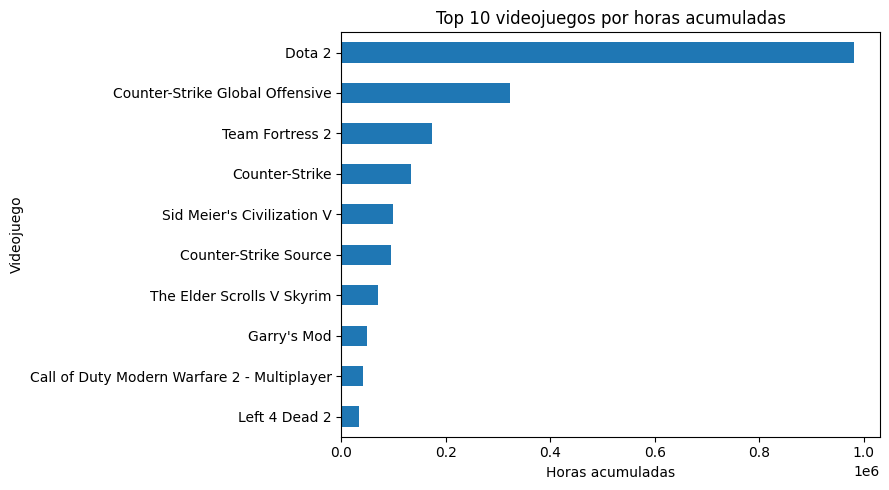

In [ ]:
# Información visual sobre los datos que se encuentran en el data set

juegos = df[df["behavior_name"] == "play"].copy()

top_horas = (
    juegos.groupby("game_title")["value"]
    .sum()
    .nlargest(10)
    .sort_values()
)

top_horas.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 videojuegos por horas acumuladas")
plt.xlabel("Horas acumuladas")
plt.ylabel("Videojuego")
plt.tight_layout()
plt.show()

2. Preparación de los datos.

Realiza el preprocesamiento necesario para aplicar técnicas de clustering.
Debes justificar cada decisión tomada.

In [ ]:
# Limpieza de datos

df_limpio = df[
    ["user_id", "game_title", "behavior_name", "value"]
].copy()

In [ ]:
# Tranformación de datos

df_limpio["value"] = pd.to_numeric(
    df_limpio["value"], errors="coerce"
)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199293 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user_id        199293 non-null  int64  
 1   game_title     199293 non-null  object 
 2   behavior_name  199293 non-null  object 
 3   value          199293 non-null  float64
 4   extra_column   199293 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 9.1+ MB


In [ ]:
# normalizar los textos

df_limpio["game_title"] = df_limpio["game_title"].str.strip()
df_limpio["behavior_name"] = (
    df_limpio["behavior_name"].str.strip().str.lower()
)

df.head()

,user_id,game_title,behavior_name,value,extra_column
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0


In [ ]:
# Eliminar información que no es relevante para analisis

df_limpio = df_limpio.dropna(
    subset=["user_id", "game_title", "behavior_name", "value"]
)

In [ ]:
# Conservar datos importantes

df_limpio = df_limpio[
    df_limpio["behavior_name"].isin(["purchase", "play"]) &
    df_limpio["game_title"].ne("") &
    (df_limpio["value"] >= 0)
].copy()

In [ ]:
# Eliminar duplicados exactos

df_limpio = df_limpio.drop_duplicates()

print("Registros después de la limpieza:", len(df_limpio))

Registros después de la limpieza: 199290


Justificación de las acciones tomadas

Durante el proceso de analisis inicial se eliminan duplicados exactos, pero no se eliminan automáticamente todas las filas que comparten el mismo usuario, juego o compra realizada: primero habría que comprobar si representan registros legítimos antes de no considerarlos en el analisis final.

Se elimina la fila de "Extra info" ya que esta no nos brinda información relevante para el analisis que se va a realizar en esta ocasión.

Se eliminan datos incompletos que no afecten el analisis de los datos, ya que no aportan información para el tipo de analisis que se va a realizar

In [ ]:
# Separar compras de tiempo de juego

compras = df_limpio[
    df_limpio["behavior_name"] == "purchase"
]

partidas = df_limpio[
    df_limpio["behavior_name"] == "play"
]


In [ ]:
# Cantidad de juegos comprados por usuario

compras_usuario = (
    compras.groupby("user_id")["game_title"]
    .nunique()
    .rename("games_purchased")
)

In [ ]:
# Tiempo de juego por usuario

horas_juego = (
    partidas.groupby(["user_id", "game_title"])["value"]
    .sum()
    .reset_index()
)

In [ ]:
# Caracteristicas de actividad

actividad_usuario = (
    horas_juego.groupby("user_id")
    .agg(
        games_played=("game_title", "nunique"),
        total_hours=("value", "sum"),
        avg_hours_per_game=("value", "mean")
    )
)

In [ ]:
usuarios = pd.concat(
    [compras_usuario, actividad_usuario],
    axis=1
).fillna(0)

print("Dimensiones de la tabla de usuarios:", usuarios.shape)
display(usuarios.head())

Dimensiones de la tabla de usuarios: (12393, 4)


,games_purchased,games_played,total_hours,avg_hours_per_game
user_id,,,,
5250,21,6.0,225.5,37.583333
76767,36,20.0,1227.0,61.350000
86540,82,15.0,255.0,17.000000
103360,10,0.0,0.0,0.000000
144736,8,1.0,0.1,0.100000


Modelado de los datos

Algoritmo implementado para el ejercicio en cuestión

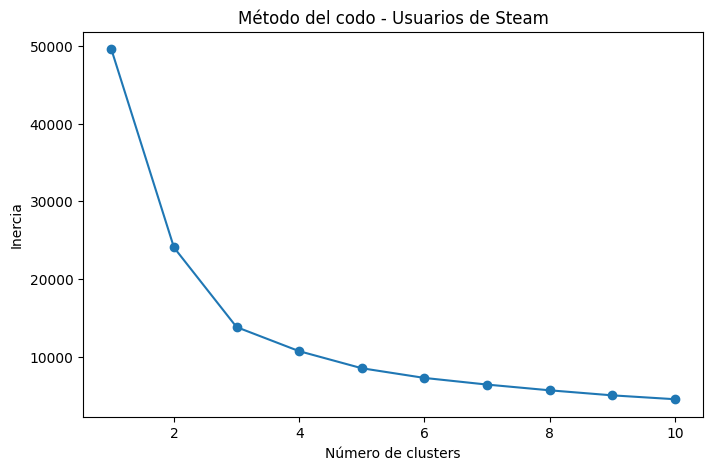

In [ ]:
inercia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inercia, marker='o')
plt.title('Método del codo - Usuarios de Steam')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.show()


In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

usuarios['cluster'] = kmeans.fit_predict(X_scaled)

print("Cantidad de usuarios por cluster:")
print(usuarios['cluster'].value_counts().sort_index())

Cantidad de usuarios por cluster:
cluster
0    1676
1    3244
2     873
3    1783
4    4817
Name: count, dtype: int64


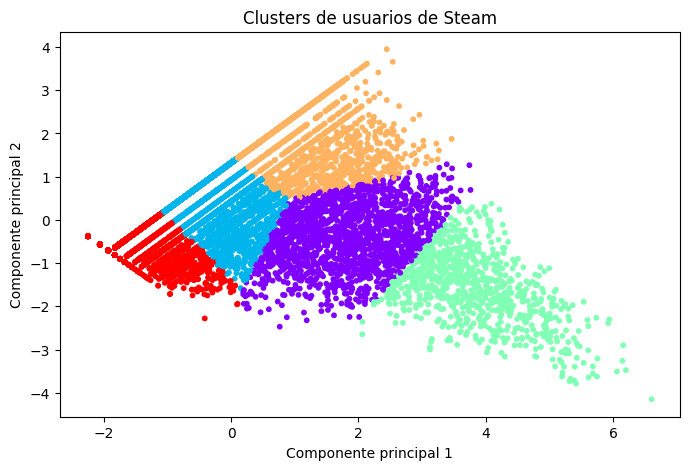

In [ ]:
pca = PCA(n_components=2)

componentes = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    componentes[:, 0],
    componentes[:, 1],
    c=usuarios['cluster'],
    cmap='rainbow',
    s=10
)

plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Clusters de usuarios de Steam')
plt.show()

In [ ]:
resumen = usuarios.groupby("cluster").agg({
    "games_purchased": "mean",
    "games_played": "mean",
    "total_hours": "mean",
    "avg_hours_per_game": "mean"
}).round(2)

# Agregar cantidad de usuarios por cluster
resumen["Cantidad de usuarios"] = usuarios.groupby("cluster").size()

# Renombrar las columnas
resumen = resumen.rename(columns={
    "games_purchased": "Compras promedio",
    "games_played": "Juegos jugados promedio",
    "total_hours": "Horas totales promedio",
    "avg_hours_per_game": "Horas promedio por juego"
})

# Organizar las columnas
resumen = resumen[
    [
        "Cantidad de usuarios",
        "Compras promedio",
        "Juegos jugados promedio",
        "Horas totales promedio",
        "Horas promedio por juego"
    ]
]

display(resumen)

,Cantidad de usuarios,Compras promedio,Juegos jugados promedio,Horas totales promedio,Horas promedio por juego
cluster,,,,,
0,1676,14.55,8.69,455.19,54.57
1,3244,2.34,1.56,23.98,17.82
2,873,93.53,49.66,1683.87,44.34
3,1783,3.19,1.75,633.19,408.32
4,4817,1.97,0.91,1.18,1.06


In [ ]:
display(
    resumen.sort_values(
        by="Horas totales promedio",
        ascending=False
    )
)

,Cantidad de usuarios,Compras promedio,Juegos jugados promedio,Horas totales promedio,Horas promedio por juego
cluster,,,,,
2,873,93.53,49.66,1683.87,44.34
3,1783,3.19,1.75,633.19,408.32
0,1676,14.55,8.69,455.19,54.57
1,3244,2.34,1.56,23.98,17.82
4,4817,1.97,0.91,1.18,1.06


Descripción de los datos encontrados:

- Cluster 1: Se puede interpretar de los datos analizados que en este grupo los jugadores son casuales, que dedican poco tiempo a juegos en comparación a otros grupos, así mismo, pocas compras se identificaron en este grupo

- Cluster 2: En este grupo encontramos que son pocos jugadores en comparación a los otros grupos, pero son los que más dedican su tiempo a jugar una variedad de juegos y dedican muchas horas a todos estos juegos, según el promedio suelen dedicar una alta cantidad de horas en promedio por cada juego que tienen en su galería.

- Cluster 3: En este grupo se caracteriza porque son jugadores que no cuenta con muchos juegos, pero que dedican muchisimas horas de juego a los juegos que tienen, podría definirse como jugares que se especializan en algún juego en particular según los datos presentados.

- Cluster 4: Son el grupo de usuarios de Steam que presenta menor actividad en la plataforma y son la mayor cantidad de cantidad de usuarios presentados en la plataforma.

- Cluster 0: Son el grupo con jugadores que se dedican a varios juegos en comparación del cluster 2, dedican tiempo a varios juegos, pero no son tiempos superiores a los de otros jugares.

Recomendaciones de negocio

Con base en los segmentos encontrados, responde:

    • Qué estrategia de marketing implementarías para cada grupo?
    • Qué tipo de promociones recibiría cada segmento?
    • Qué usuarios priorizarías para campañas de fidelización?
    
Qué información adicional sería útil para mejorar la segmentación?



- ¿Qué estrategia de marketing implementarías para cada grupo?

   La estrategía que implementaría para cada grupo estaría enfocada en los intereses que ya los datos me han suministrado.

   Cluster 0: Bucaría brindarles más ofertas de juego e incentivos para aumentar su interactividad en Steam, dandole recomendaciones relacionadas a los juegos que ya cuenta en su galería.

   Cluster 1: Buscaría generar ofertas de tiempo límitado por usuario, enviando mensajes dirigidos a incentivar su retorno a la plataforma.

   Cluster 2: Promocionar e incentivar a los jugadores activos constantes brindandoles ofertas por fidelidad o antiguedad en la plataforma con el fin de seguir incentivando las compras y demostrandole al consumidor "el valor relevante que tiene para la plataforma"

   Cluster 3: Determinando los patrones de juego, buscaría brindarle beneficios en cada juego que cada jugador dedica su tiempo, permitiendo ofertas de paquetes de contenido exclusivo, expansiones o servicios que sigan incentivando su constancia en el juego al que dedica tiempo.

   Cluster 4: Intentaría buscar generar campañas de reactivación o crear campañas en torno al beneficio de jugar videojuegos, aprovecharía el alcance de la plataforma para enviar ofertas e incentivos que sean a bajo costo con el fin de "incentivar un hobbie en sus vidas"

- Qué usuarios priorizarías para campañas de fidelización?
  
  Con base en la información recopilada, puedo determinar que la prioridad estaría en la retención de usuarios que ya se encuentran en la plataforma, desde los que dedican la mayoría de su tiempo a jugar una gran variedad, como aquellos jugadores que dedican muchas horas en 1 juego en especifico,

  Cluster 3: La prioridad sería ofrecerles actualizaciones innovadoras e incentivar a los desarrolladores a generar la retención de sus usuarios, ofreciendo descuentos, horas de juego que puedan aprovechar los jugadores y que reciban recompensas durante este tiempo
  Cluster.

  Cluster 0: Este grupo tiene un alto potencial como usuarios activos en la plataforma, ya que son jugadores que no son casuales, pero tampoco invierten altas cantidades de tiempo o variedad de juegos en comparación a otros grupos, por lo que buscaría incentivarlos y atraerlos a juegos que se relacionen a su galería por medio de recomendaciones a precios en oferta limitada, así mismo, buscaría incentivarlos jugando estos juegos por medio de premios por tiempo jugado o recompensas que los motiven a dedicar más ti

